In [33]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

In [34]:
tickers = ["^FTAS", "^FTMC", "PSN.L", "TW.L", "LLOY.L", "NWG.L", "IGLT.L"]
data = yf.download(tickers, start="2013-01-01", end="2026-10-01", auto_adjust=True)
prices = data["Close"]
prices = prices.dropna(how="all")

prices.to_csv("prices.csv") 
              #save a copy so no redownloading for me
prices.tail()

[*********************100%***********************]  7 of 7 completed


Ticker,IGLT.L,LLOY.L,NWG.L,PSN.L,TW.L,^FTAS,^FTMC
Date,,,,,,,
2026-09-24,9.4975,107.000000,684.599976,1148.316895,78.787743,5752.890137,24154.300781
2026-09-25,9.5125,108.800003,694.400024,1154.316040,80.087532,5763.080078,24261.099609
2026-09-28,9.4800,108.099998,690.000000,1323.788940,89.306099,5760.310059,24335.300781
2026-09-29,9.4875,107.500000,688.000000,1329.288086,87.226418,5738.600098,24374.800781
2026-09-30,9.4850,106.900002,688.400024,1314.790405,85.986618,5728.410156,24540.000000


In [35]:
print(prices.shape)
print(prices.isna().sum())
print(prices.apply(lambda col:col.first_valid_index()))

(3474, 7)
Ticker
IGLT.L    1
LLOY.L    0
NWG.L     0
PSN.L     0
TW.L      0
^FTAS     0
^FTMC     0
dtype: int64
Ticker
IGLT.L   2013-01-02
LLOY.L   2013-01-02
NWG.L    2013-01-02
PSN.L    2013-01-02
TW.L     2013-01-02
^FTAS    2013-01-02
^FTMC    2013-01-02
dtype: datetime64[s]


In [36]:
returns = prices.pct_change(fill_method=None)
returns = returns.iloc[1:]   #drop the first row (empty)
returns.describe().round(4)

Ticker,IGLT.L,LLOY.L,NWG.L,PSN.L,TW.L,^FTAS,^FTMC
count,3471.0000,3473.0000,3473.0000,3473.0000,3473.0000,3473.0000,3473.0000
mean,0.0000,0.0004,0.0004,0.0004,0.0003,0.0002,0.0002
std,0.0053,0.0184,0.0209,0.0220,0.0214,0.0090,0.0098
min,-0.0489,-0.2100,-0.1804,-0.2755,-0.2926,-0.1049,-0.0935
25%,-0.0029,-0.0086,-0.0104,-0.0105,-0.0102,-0.0039,-0.0045
50%,0.0000,0.0000,0.0008,0.0007,0.0007,0.0006,0.0005
75%,0.0028,0.0092,0.0113,0.0111,0.0112,0.0046,0.0054
max,0.0719,0.1357,0.1372,0.1528,0.1861,0.0886,0.0837


In [37]:
ESTIMATION_WINDOW = (-250, -30)
EVENT_WINDOW = (-1,5)

In [38]:
def event_study(returns, asset, market, event_date):
    event_date = pd.Timestamp(event_date)
    idx = returns.index.get_indexer([event_date],method="bfill")[0]
    
    est = returns.iloc[idx + ESTIMATION_WINDOW[0] : idx + ESTIMATION_WINDOW[1]]
    est = est.dropna(subset=[asset, market])
    beta, alpha = np.polyfit(est[market], est[asset], 1)
    predicted = alpha +beta *est[market]
    resid_sd = (est[asset] - predicted).std()
    
    win = returns.iloc[idx + EVENT_WINDOW[0] : idx + EVENT_WINDOW[1] + 1].copy()
    win["expected"] = alpha + beta * win[market]
    win["abnormal"] = win[asset] - win["expected"]
    win["CAR"] = win["abnormal"].cumsum()
    win["day"] = range(EVENT_WINDOW[0], EVENT_WINDOW[1] + 1)
    
    car = win["CAR"].iloc[-1]
    t_stat = car / (resid_sd * np.sqrt(len(win)))
    return win, car, t_stat, beta 


In [39]:
win, car, t, beta = event_study(returns, "PSN.L", "^FTAS", "2022-09-23")
print(win[["PSN.L", "^FTAS", "expected", "abnormal", "CAR", "day"]].round(4))
print(f"Beta: {beta:.2f}, CAR: {car:.2%}, t-stat:{t:2f}")

Ticker       PSN.L   ^FTAS  expected  abnormal     CAR  day
Date                                                       
2022-09-22 -0.0175 -0.0123   -0.0151   -0.0024 -0.0024   -1
2022-09-23 -0.0185 -0.0194   -0.0229    0.0043  0.0019    0
2022-09-26 -0.0622 -0.0019   -0.0038   -0.0584 -0.0565    1
2022-09-27 -0.0458 -0.0081   -0.0105   -0.0353 -0.0918    2
2022-09-28  0.0348  0.0026    0.0010    0.0337 -0.0580    3
2022-09-29 -0.0600 -0.0197   -0.0231   -0.0369 -0.0949    4
2022-09-30  0.0532  0.0049    0.0036    0.0496 -0.0453    5
Beta: 1.09, CAR: -4.53%, t-stat:-0.979583


In [40]:
events = pd.read_csv("events.csv", parse_dates=["date"])
events

,event,date,type
0,Scottish independence referendum result,2014-09-19,referendum
1,2015 general election result,2015-05-08,election
2,Brexit referendum result,2016-06-24,referendum
3,2017 general election result,2017-06-09,election
4,2019 general election result,2019-12-13,election
5,Truss mini-budget,2022-09-23,fiscal
6,Truss resignation,2022-10-20,leadership
7,2024 general election result,2024-07-05,election
8,Autumn Budget 2024,2024-10-30,fiscal


In [41]:
csv_text = """event,date,type
Scottish independence referendum result,2014-09-19,referendum
2015 general election result,2015-05-08,election
Brexit referendum result,2016-06-24,referendum
2017 general election result,2017-06-09,election
2019 general election result,2019-12-13,election
Truss mini-budget,2022-09-23,fiscal
Truss resignation,2022-10-20,leadership
2024 general election result,2024-07-05,election
Autumn Budget 2024,2024-10-30,fiscal
"""

with open("events.csv", "w") as f:
    f.write(csv_text)

print("events.csv created")

events.csv created


In [45]:
assets = ["PSN.L", "TW.L", "LLOY.L", "NWG.L", "^FTMC", "IGLT.L"]
rows = []

for _, ev in events.iterrows():
    for asset in assets:
        try:
            win, car, t, beta = event_study(returns,asset, "^FTAS", ev["date"])
            rows.append({
                "event": ev["event"],
                "type": ev["type"],
                "asset": asset,
                "beta": round(beta, 2),
                "CAR_%": round(car * 100, 2),
                "t_stat": round(t, 2)})
        except Exception as e:
            print (f"Skipped {asset} for {ev['event']}: {e}")

results = pd.DataFrame(rows)
results.to_csv("results.csv", index=False)
print(results.shape)

(54, 6)


In [46]:
results.sort_values("CAR_%").head(10)

,event,type,asset,beta,CAR_%,t_stat
15,Brexit referendum result,referendum,NWG.L,1.22,-37.21,-9.63
12,Brexit referendum result,referendum,PSN.L,0.83,-27.41,-6.43
13,Brexit referendum result,referendum,TW.L,0.92,-26.30,-6.30
14,Brexit referendum result,referendum,LLOY.L,1.10,-26.08,-7.32
48,Autumn Budget 2024,fiscal,PSN.L,1.58,-15.73,-3.59
49,Autumn Budget 2024,fiscal,TW.L,1.27,-10.99,-3.38
31,Truss mini-budget,fiscal,TW.L,1.25,-10.62,-2.46
33,Truss mini-budget,fiscal,NWG.L,1.33,-8.66,-2.18
32,Truss mini-budget,fiscal,LLOY.L,1.53,-7.27,-1.94
16,Brexit referendum result,referendum,^FTMC,0.76,-5.57,-6.25


In [50]:
significant = results[results["t_stat"].abs() > 2]
significant

,event,type,asset,beta,CAR_%,t_stat
6,2015 general election result,election,PSN.L,1.12,10.67,2.73
7,2015 general election result,election,TW.L,1.12,11.14,2.67
8,2015 general election result,election,LLOY.L,1.02,6.55,2.86
10,2015 general election result,election,^FTMC,0.83,2.51,2.53
12,Brexit referendum result,referendum,PSN.L,0.83,-27.41,-6.43
13,Brexit referendum result,referendum,TW.L,0.92,-26.30,-6.30
14,Brexit referendum result,referendum,LLOY.L,1.10,-26.08,-7.32
15,Brexit referendum result,referendum,NWG.L,1.22,-37.21,-9.63
16,Brexit referendum result,referendum,^FTMC,0.76,-5.57,-6.25
17,Brexit referendum result,referendum,IGLT.L,-0.19,5.83,5.22


In [51]:
summary = results.pivot_table(index="type",
                              columns="asset", values="CAR_%", aggfunc="mean")
summary.round(2)

asset,IGLT.L,LLOY.L,NWG.L,PSN.L,TW.L,^FTMC
type,,,,,,
election,-0.02,1.68,0.51,1.96,4.61,1.40
fiscal,-2.92,-4.12,-0.96,-10.13,-10.80,-1.42
leadership,6.87,-2.52,1.48,3.56,4.67,1.55
referendum,3.08,-10.69,-16.38,-13.26,-11.60,-2.49


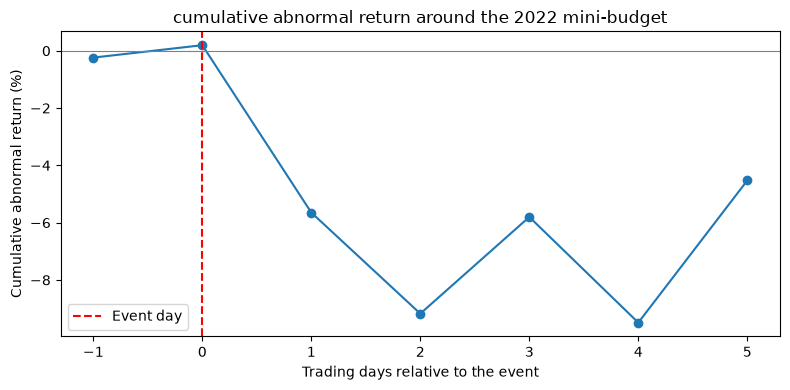

In [56]:
win, car, t, beta = event_study(returns, "PSN.L", "^FTAS", "2022-09-23")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(win["day"], win["CAR"] * 100, marker="o")
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="red", linestyle="--", label="Event day")
ax.set_title("cumulative abnormal return around the 2022 mini-budget")
ax.set_xlabel("Trading days relative to the event")
ax.set_ylabel("Cumulative abnormal return (%)")
ax.legend()
fig.tight_layout()
fig.savefig("minibudget_persimmon.png", dpi=150)
plt.show()

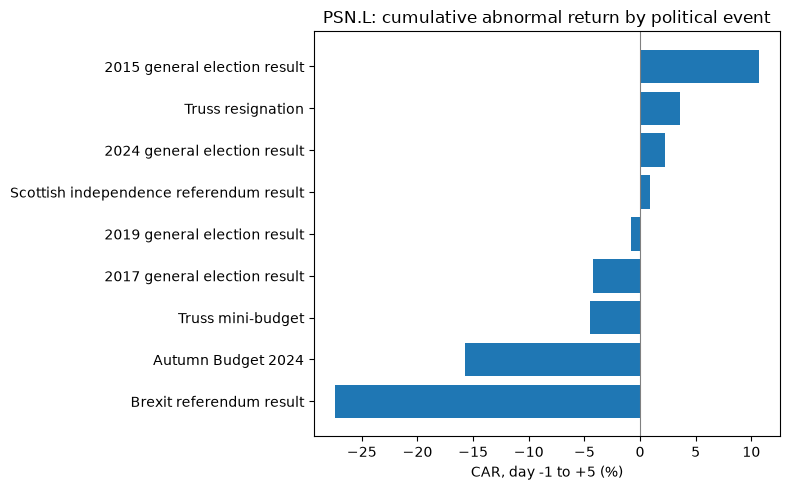

In [55]:
asset = "PSN.L"
sub = results[results["asset"] == asset].sort_values("CAR_%")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(sub["event"], sub["CAR_%"])
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_title(f"{asset}: cumulative abnormal return by political event")
ax.set_xlabel("CAR, day -1 to +5 (%)")
fig.tight_layout()
fig.savefig(f"{asset}_all_events.png", dpi=150)
plt.show()